# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [9]:
df = pd.read_csv("/kaggle/input/datasets/heshyb/salary-data-csv/Salary_Data.csv")   # e.g., "Salary_Data.csv"
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [12]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

df.info()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [13]:
X = df[[ "YearsExperience" ]]     # YearsExperience
y = df["Salary"]           # Salary

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 25321.583011776813
Coefficient: 9423.815323030976


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [17]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

,YearsExperience,ActualSalary,PredictedSalary
0,9.6,112635.0,115790.210113
1,4.9,67938.0,71498.278095
2,8.2,113812.0,102596.868661
3,5.3,83088.0,75267.804224
4,3.2,64445.0,55477.792045


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 =r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6286.453830757749
MSE : 49830096.85590839
RMSE: 7059.04362190151
R^2 : 0.9024461774180497


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

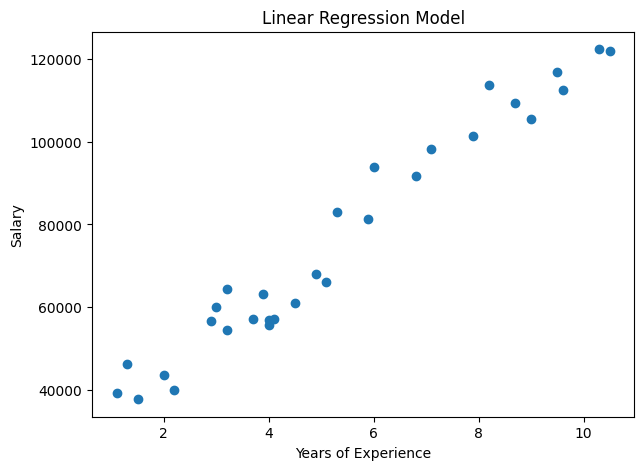

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(df["YearsExperience"], df["Salary"])
plt.title("Linear Regression Model")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

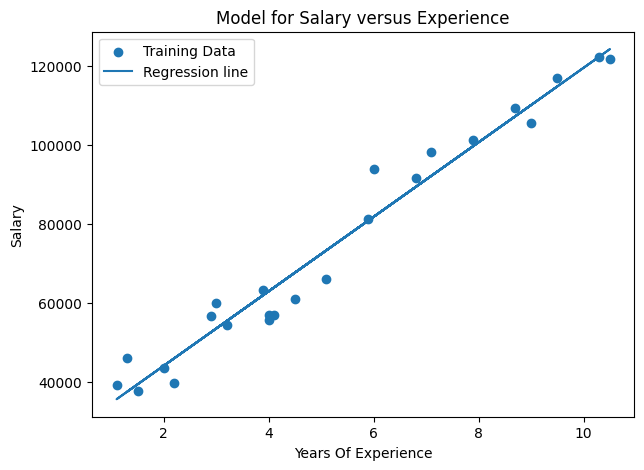

In [22]:
plt.figure(figsize=(7, 5))
plt.scatter(X_train["YearsExperience"], y_train, label="Training Data")

y_train_line = model.predict(X_train)
plt.plot(X_train["YearsExperience"], y_train_line, label="Regression line")

plt.title("Model for Salary versus Experience")
plt.xlabel("Years Of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

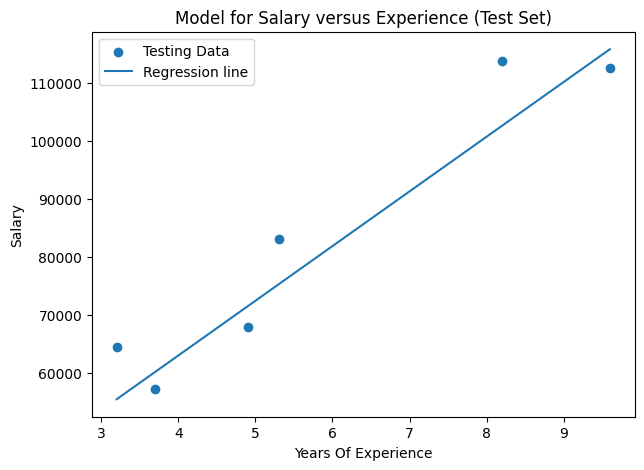

In [24]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test["YearsExperience"], y_test, label="Testing Data")

X_line = X_test.sort_values(by="YearsExperience")
y_line = model.predict(X_line)

plt.plot(X_line["YearsExperience"], y_line, label="Regression line")

plt.title("Model for Salary versus Experience (Test Set)")
plt.xlabel("Years Of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

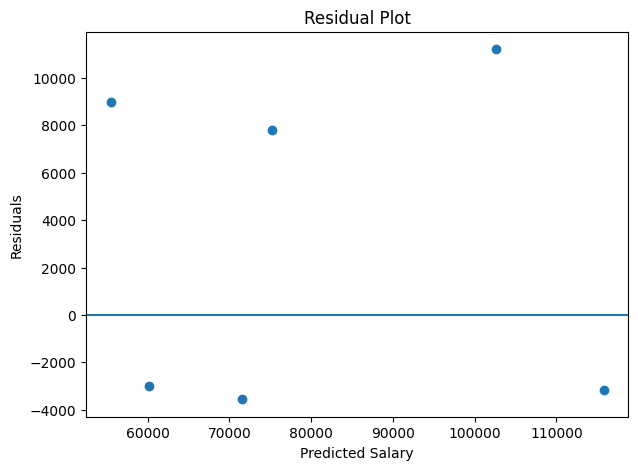

In [25]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.title("Residual Plot")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [ ]:
# Exercise A:
# The slope represents the salary increase per additional year of experience.

# Exercise B:
# It means this model is a good predictor for the salary.

# Exercise C:
# Outliers can weaken the regression line and the prediction itself.

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [ ]:
# YOUR CODE HERE